In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_tow104_notrueptcons.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [6]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [7]:
print(df_match.shape[0], df_allfake.shape[0])

2672522 1498016


In [8]:
print(np.unique(df_match['bs']))

[-1  1]


In [9]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [10]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [11]:
plt.rcParams['font.size'] = 12

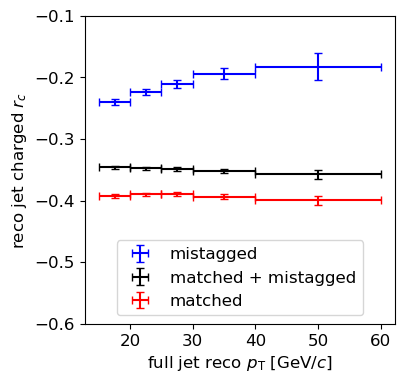

In [12]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [13]:
rc_allfake_bs_vs_pts_array

[-0.23941091861126734,
 -0.22363042330897315,
 -0.21057110978677787,
 -0.19412476411120946,
 -0.18292625944306976]

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [15]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [16]:
b_fake_array

[array([0.61970546, 0.38029454]),
 array([0.61181521, 0.38818479]),
 array([0.60528555, 0.39471445]),
 array([0.59706238, 0.40293762]),
 array([0.59146313, 0.40853687])]

In [17]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [18]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

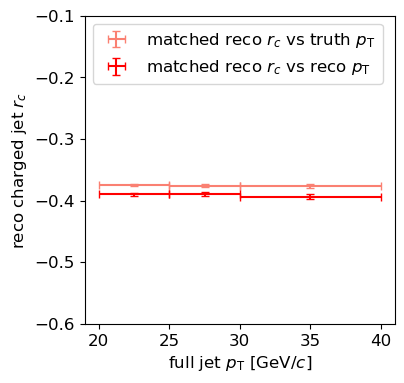

In [19]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [20]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69615206 0.30384794]
[0.69502892 0.30497108]
[0.69481038 0.30518962]
[0.69710319 0.30289681]
[0.69991226 0.30008774]


In [21]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2718644/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [22]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.30417349, 0.25359598, 0.22686195, 0.20998996, 0.19506776])

Process data

In [23]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [24]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [25]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [26]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [27]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [28]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [29]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[240151.21246506 118518.12918777]
[490.05225483 344.26462088]
1
[72379. 38554.]
[55167.31504763 27633.52245542]
[234.87723399 166.23333738]
2
[16450.  8688.]
[12998.14379529  6437.00045869]
[114.00940222  80.23091959]
3
[4758. 2573.]
[3838.86043497 1952.70316331]
[61.95853803 44.18940103]
4
[334. 153.]
[277.81218711 114.18981544]
[16.66769891 10.68596348]


In [30]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

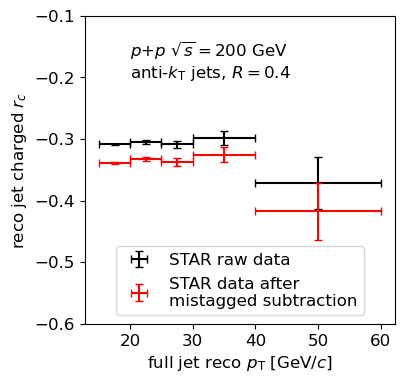

In [31]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [32]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [33]:
reweight_array

[array([0.96180364, 1.08751244]),
 array([0.95861505, 1.09431626]),
 array([0.96255881, 1.08524054]),
 array([0.95084434, 1.11312951]),
 array([1.01255683, 0.97071298])]

([], [])

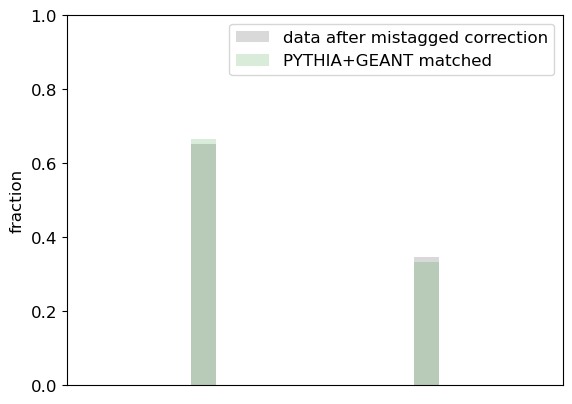

In [34]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [35]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 65.11172673922925
anomaly reco pT: 60.32372097584812
anomaly reco pT: 63.98661600986461
anomaly reco pT: 63.98721524948687
anomaly reco pT: 61.230547069716295
anomaly reco pT: 60.489865724633745
anomaly reco pT: 61.0145432433836
anomaly reco pT: 60.414293149512936
anomaly reco pT: 61.72805415814309
anomaly reco pT: 64.96868135884245
anomaly reco pT: 62.19869855886694
anomaly reco pT: 66.46656472583156
anomaly reco pT: 60.38457174077097
anomaly reco pT: 63.121900427163816
anomaly reco pT: 60.343144569675786
anomaly reco pT: 60.70409277962416
anomaly reco pT: 60.99402252749229
anomaly reco pT: 63.080112112209726
anomaly reco pT: 60.653504621892836
anomaly reco pT: 61.525768657044004
anomaly reco pT: 60.936545329465915
anomaly reco pT: 64.19633890500573
anomaly reco pT: 60.63742794816389
anomaly reco pT: 62.96484158586213
anomaly reco pT: 60.483137163454344
anomaly reco pT: 61.91730187357032
anomaly reco pT: 64.70320135687591
anomaly reco pT: 64.49991473215765
anomaly rec

anomaly reco pT: 63.00547890133483
anomaly reco pT: 62.16104493202202
anomaly reco pT: 63.48087820714415
anomaly reco pT: 61.287455974516355
anomaly reco pT: 63.69876978365224
anomaly reco pT: 61.84823254866114
anomaly reco pT: 61.627799172954425
anomaly reco pT: 60.70587250388569
anomaly reco pT: 61.77168672988331
anomaly reco pT: 60.879878536335106
anomaly reco pT: 60.339987611364336
anomaly reco pT: 61.25062682942063
anomaly reco pT: 61.88871623455996
anomaly reco pT: 62.02616912416169
anomaly reco pT: 69.1177932791854
anomaly reco pT: 63.486798618393316
anomaly reco pT: 60.615335221187976
anomaly reco pT: 62.44206114234046
anomaly reco pT: 72.18297838873072
anomaly reco pT: 62.286510533466355
anomaly reco pT: 66.71966428733958
anomaly reco pT: 60.77821300130781
anomaly reco pT: 66.44112539253962
anomaly reco pT: 68.87884289646634
anomaly reco pT: 60.12499688529351
anomaly reco pT: 66.95999249105057
anomaly reco pT: 61.80802164245639
anomaly reco pT: 61.576979716200796
anomaly reco 

anomaly reco pT: 63.14818076389776
anomaly reco pT: 64.32961998720666
anomaly reco pT: 62.792551820714245
anomaly reco pT: 62.154125187631024
anomaly reco pT: 63.86574356656586
anomaly reco pT: 62.21589178816643
anomaly reco pT: 60.36831127728506
anomaly reco pT: 60.42201147051878
anomaly reco pT: 63.36692267680514
anomaly reco pT: 67.04493184665876
anomaly reco pT: 65.64382815674513
anomaly reco pT: 61.53672606650915
anomaly reco pT: 61.6754074675169
anomaly reco pT: 63.169049563843046
anomaly reco pT: 60.08543931860479
anomaly reco pT: 62.906468389076984
anomaly reco pT: 60.0784840952256
anomaly reco pT: 61.549417189922096
anomaly reco pT: 60.66091965769004
anomaly reco pT: 61.16795017442313
anomaly reco pT: 64.11989223761948
anomaly reco pT: 73.59594226925768
anomaly reco pT: 61.66800660882226
anomaly reco pT: 65.93296111640436
anomaly reco pT: 67.13854271244278
anomaly reco pT: 61.397383653749294
anomaly reco pT: 61.34032493040032
anomaly reco pT: 61.79055671413054
anomaly reco pT:

anomaly reco pT: 62.89092595953631
anomaly reco pT: 64.10207633010019
anomaly reco pT: 65.71781259026629
anomaly reco pT: 60.27807811476955
anomaly reco pT: 60.88464900772536
anomaly reco pT: 63.14496995123857
anomaly reco pT: 62.62610601549029
anomaly reco pT: 61.86764490750105
anomaly reco pT: 63.43314140604081
anomaly reco pT: 71.06158798692796
anomaly reco pT: 70.82944670797608
anomaly reco pT: 65.31680467591607
anomaly reco pT: 60.03289506516748
anomaly reco pT: 60.32919578693263
anomaly reco pT: 63.04150962231807
anomaly reco pT: 61.57997799318933
anomaly reco pT: 61.67383746954961
anomaly reco pT: 66.66380117803303
anomaly reco pT: 61.88435402810025
anomaly reco pT: 62.874838762442266
anomaly reco pT: 60.127503199500225
anomaly reco pT: 64.22785476411943
anomaly reco pT: 63.468489680708565
anomaly reco pT: 61.17011203661938
anomaly reco pT: 61.59500787117579
anomaly reco pT: 65.28723161454938
anomaly reco pT: 63.229924041948834
anomaly reco pT: 60.492609863503304
anomaly reco pT

anomaly reco pT: 64.79063459979419
anomaly reco pT: 60.20168825096363
anomaly reco pT: 65.65119286212685
anomaly reco pT: 65.30271319857162
anomaly reco pT: 61.5936269340781
anomaly reco pT: 60.265340451694804
anomaly reco pT: 64.28249716597105
anomaly reco pT: 62.49848713561286
anomaly reco pT: 61.01709951921005
anomaly reco pT: 60.47738885730147
anomaly reco pT: 60.66154227046318
anomaly reco pT: 62.00914314289796
anomaly reco pT: 60.38593485912751
anomaly reco pT: 60.27477001269559
anomaly reco pT: 60.483665131882965
anomaly reco pT: 64.57153026884265
anomaly reco pT: 62.58457130553776
anomaly reco pT: 63.89168324368338
anomaly reco pT: 60.92112745922757
anomaly reco pT: 62.49213245408136
anomaly reco pT: 63.45245818175565
anomaly reco pT: 62.989565446441084
anomaly reco pT: 69.05239695884698
anomaly reco pT: 62.94711156192044
anomaly reco pT: 70.64080816113271
anomaly reco pT: 66.11953625071365
anomaly reco pT: 63.11605695986804
anomaly reco pT: 64.11953271602735
anomaly reco pT: 6

anomaly reco pT: 62.94157898271905
anomaly reco pT: 61.3177457202157
anomaly reco pT: 68.08191821159342
anomaly reco pT: 60.421024502813204
anomaly reco pT: 61.47523687942781
anomaly reco pT: 63.96210666017679
anomaly reco pT: 62.735643781023
anomaly reco pT: 60.181940147773105
anomaly reco pT: 61.9321131057092
anomaly reco pT: 62.01747862049769
anomaly reco pT: 75.1833190314242
anomaly reco pT: 61.76367462114445
anomaly reco pT: 66.82835537000965
anomaly reco pT: 62.14829924643138
anomaly reco pT: 67.3748002175073
anomaly reco pT: 66.34252356385487
anomaly reco pT: 66.90906811293705
anomaly reco pT: 61.183990023187434
anomaly reco pT: 62.29097747077919
anomaly reco pT: 61.16676271827074
anomaly reco pT: 64.8523928535017
anomaly reco pT: 62.08927162634519
anomaly reco pT: 61.24191886150412
anomaly reco pT: 65.16798365744793
anomaly reco pT: 61.71191324059416
anomaly reco pT: 61.41450816008402
anomaly reco pT: 60.038954043961766
anomaly reco pT: 62.284114074809295
anomaly reco pT: 60.90

... (55 outputs left out)

anomaly reco pT: 60.217141764950824
anomaly reco pT: 61.39291394252393
anomaly reco pT: 63.77618345378384
anomaly reco pT: 60.233081989855464
anomaly reco pT: 63.57720261731494
anomaly reco pT: 65.15042036512062
anomaly reco pT: 67.78096533218765
anomaly reco pT: 64.84559189199464
anomaly reco pT: 62.860803013868164
anomaly reco pT: 60.29695635575036
anomaly reco pT: 61.877506318936696
anomaly reco pT: 63.99731759244105
anomaly reco pT: 66.90052213417196
anomaly reco pT: 66.2209770886722
anomaly reco pT: 60.11622291752129
anomaly reco pT: 63.38299536822333
anomaly reco pT: 61.33441223698607
anomaly reco pT: 62.087655052125044
anomaly reco pT: 60.410691293566686
anomaly reco pT: 61.68872782287461
anomaly reco pT: 60.63466404334116
anomaly reco pT: 72.95515893986668
anomaly reco pT: 60.0109457757214
anomaly reco pT: 60.24047909647852
anomaly reco pT: 60.85485357773569
anomaly reco pT: 62.76878674334641
anomaly reco pT: 73.07436046857389
anomaly reco pT: 64.28383042270804
anomaly reco pT:

anomaly reco pT: 60.91239449646827
anomaly reco pT: 66.65181977342894
anomaly reco pT: 60.753400783790454
anomaly reco pT: 61.19011273143979
anomaly reco pT: 72.90960627977708
anomaly reco pT: 62.7800941176184
anomaly reco pT: 64.57363118027455
anomaly reco pT: 61.742917584584475
anomaly reco pT: 61.382522590419434
anomaly reco pT: 61.88766097856808
anomaly reco pT: 61.89574538975657
anomaly reco pT: 61.09603012758164
anomaly reco pT: 63.63747162193641
anomaly reco pT: 60.699307171587535
anomaly reco pT: 65.3491995657269
anomaly reco pT: 60.21922657629564
anomaly reco pT: 60.72096660173939
anomaly reco pT: 62.3819267976767
anomaly reco pT: 62.93362579342403
anomaly reco pT: 62.46294999610992
anomaly reco pT: 66.67157539603932
anomaly reco pT: 61.8132454427371
anomaly reco pT: 60.03731880060585
anomaly reco pT: 65.81593768184928
anomaly reco pT: 62.7668154263134
anomaly reco pT: 60.660101429362456
anomaly reco pT: 64.14463580481024
anomaly reco pT: 61.6960595030621
anomaly reco pT: 60.3

anomaly reco pT: 75.35404887253833
anomaly reco pT: 63.171317366095884
anomaly reco pT: 67.19384857430518
anomaly reco pT: 63.99706283936754
anomaly reco pT: 61.15086578456151
anomaly reco pT: 67.30720285983246
anomaly reco pT: 70.91096205044772
anomaly reco pT: 66.04287498444224
anomaly reco pT: 66.27695346755426
anomaly reco pT: 60.85316892580347
anomaly reco pT: 60.79473110794202
anomaly reco pT: 63.69243497678554
anomaly reco pT: 65.297237355898
anomaly reco pT: 60.05272392841351
anomaly reco pT: 60.51878205098013
anomaly reco pT: 64.67469469006411
anomaly reco pT: 62.46249931521838
anomaly reco pT: 60.11396418885598
anomaly reco pT: 60.58007281188299
anomaly reco pT: 60.910392784582655
anomaly reco pT: 60.195443683022845
anomaly reco pT: 60.21124304700415
anomaly reco pT: 61.328743512232094
anomaly reco pT: 62.849477888945536
anomaly reco pT: 60.38170745744913
anomaly reco pT: 62.32331565825146
anomaly reco pT: 60.12941572606424
anomaly reco pT: 63.776336127435286
anomaly reco pT:

/tmp/ipykernel_2718644/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [36]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [37]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [38]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

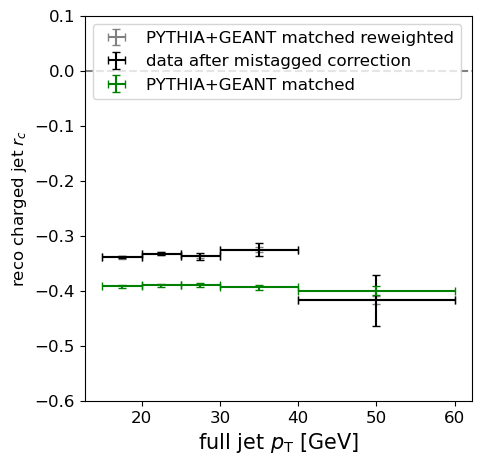

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [39]:
print(rc_match_bs_vs_pts_array_rw)

[-0.33912316764500944, -0.3325303634851479, -0.33759169733159927, -0.325673238252551, -0.41740187705105797]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

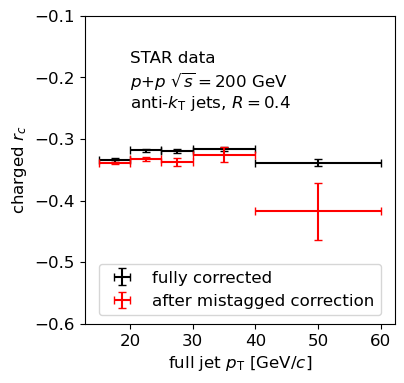

In [40]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

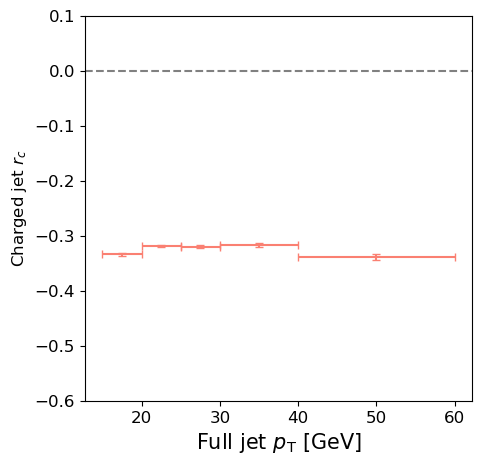

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [42]:
rc_match_bs_vs_pt_array

[-0.33410201908181153,
 -0.3186500106234434,
 -0.31976661119496513,
 -0.31609968352447787,
 -0.3385983737819121]

In [43]:
rc_err_match_bs_vs_pt_array

[0.0029898581726422457,
 0.002254814910194778,
 0.0028187115050869213,
 0.0035041951835478075,
 0.0052344531967531555]